# Task 01: Setting up

1. Create a new workspace folder and open it in VS Code.
2. Create environment named `.venv`
3. Make sure to activate the environment.
4. You have to decide which packages are to be installed, so make sure to install any required packages in the created `.venv` environment.

In [1]:
import sys
print(sys.version)


3.14.5 (tags/v3.14.5:5607950, May 10 2026, 10:43:50) [MSC v.1944 64 bit (AMD64)]


Run the following in a terminal window

```
python -m venv .venv
.\.venv\Scripts\activate
.\.venv\Scripts\python.exe -m pip install --upgrade pip
.\.venv\Scripts\python.exe -m pip install jupyter
ipython kernel install --name ".venv-task01-kernel" --user
.\.venv\Scripts\python.exe -m pip install pandas matplotlib 
.\.venv\Scripts\deactivate
```

# Task 01.01: Steam Case Study

1. The aim of this practice is to get the top 10 played games on Steam and save them to file. This are the required steps.
2. Create a Jupyter Notebook and put your code in it.
3. Access this page `https://steamcharts.com/` and identify the element that contains the top 10 games.
4. Data Acquisition
   - Use `requests` to get the response. Make sure to apply error handling to this.
   - Parse the response using Beautiful Soup.
   - Extract the table with the required content.
   - Extract the headers like `Name`, `Current Players`, etc. and store them in a list.
   - Extract all the rows storing the games and store them in another list.
5. Data Collation
   - Rename the empty field in headers to `Rank`.
   - Create a `pandas` dataframe with the extracted data making sure to set the headers to the parsed headers.
   - Show the first 3 records.
   - In column `Rank` remove the `.` from the number.
   - Change the column `Hours Played`'s data type to `int`. Then replace the existing values to days rather than hours (divide by 24). Finally, rename this column to `Days Played`.
   - Show the first 3 records again.
6. Data Saving
    - Save the cleaned dataframe to a CSV file without an index.

**P.S.** Output should be as follows:

|Rank|Name|Current Players|Last 30 Days|Peak Players|Days Played|
|-|-|-|-|-|-|
|1|Counter-Strike 2|1059251|		|1588091|28600574|
|2|Dota 2|602904|	|889520|16617569|
|3|PUBG: BATTLEGROUNDS|404339|	|750442|8265557|
|4|Escape from Duckov|260196|	|279489|985932|
|5|Battlefield™ 6|207677|	|656067|4606850|
|6|Delta Force|149450|	|246418|3202368|
|7|Wallpaper Engine|112778|		|144530|2564379|
|8|Apex Legends|106333|		|186134|2302420|
|9|Rust|103597|		|178836|2896900|
|10|Bongo Cat|94583|	|129601|2716757|


## Data acquisition 

In [2]:
import requests
from bs4 import BeautifulSoup

url = "https://steamcharts.com/"

try:
    response = requests.get(url,
                            headers={"User-Agent": "MCAST-ClassroomDemo/1.0 (educational example)"},
                            timeout=30)
    response.raise_for_status()
except requests.RequestException as error:
    print(f"Could not download the page: {error}")
else:
    soup = BeautifulSoup(response.text, "html.parser")
    print("Page downloaded and parsed successfully.")

Page downloaded and parsed successfully.


In [3]:
# Inspect the tables on the page
for table in soup.find_all("table"):
    print("ID:", table.get("id"))
    print("Classes:", table.get("class"))
    print(table.get_text(" ", strip=True)[:300])
    print()

ID: trending-recent
Classes: ['trending', 'common-table']
Name 24-hour Change Last 48 Hours Current Players LORT +578.4% 819 Railroader +290.2% 1585 REKA +247.2% 1882 Outlast +203.6% 1910 Shadowverse: Worlds Beyond +177.8% 12580

ID: top-games
Classes: ['common-table']
Name Current Players Last 30 Days Peak Players Hours Played 1. Counter-Strike 2 1062985 1402441 586649726 2. Dota 2 681459 1096364 481624192 3. PUBG: BATTLEGROUNDS 314966 806873 230995252 4. FiveM 162544 203611 91887231 5. Bongo Cat 149152 193506 112762642 6. Call of Duty® 147344 226679 43923055 7. 

ID: toppeaks
Classes: ['common-table']
Name Peak Players Time Last 48 Hours PUBG: BATTLEGROUNDS 3236027 2018-01-01T00:00:00Z Black Myth: Wukong 2406967 2024-08-01T00:00:00Z Palworld 2101535 2024-01-01T00:00:00Z Counter-Strike 2 1818368 2025-03-01T00:00:00Z Lost Ark 1324761 2022-02-01T00:00:00Z Dota 2 1291328 2016-03-01T00:00:00Z Monster 



In [4]:
# Select the top games table
table = soup.select_one("table#top-games")

if table is None:
    raise ValueError("Top games table not found!")

#Extract the column headers into a list
headers = [
    cell.get_text(" ", strip=True)
    for cell in table.find_all("th")
]

print(headers)

['', 'Name', 'Current Players', 'Last 30 Days', 'Peak Players', 'Hours Played']


In [5]:
# Extract the game rows into a list
rows = []

for row in table.find_all("tr"):
    cells = row.find_all("td")

    if cells:
        rows.append([
            cell.get_text(" ", strip=True)
            for cell in cells
        ])

rows = rows[:10]

print("Number of games:", len(rows))
print(rows[0])

Number of games: 10
['1.', 'Counter-Strike 2', '1062985', '', '1402441', '586649726']


## Data collation

In [6]:
import pandas as pd

# Name the empty first header
headers[0] = "Rank"

# Create the DataFrame and preview the first three records
df = pd.DataFrame(rows, columns=headers)
df.head(3)

,Rank,Name,Current Players,Last 30 Days,Peak Players,Hours Played
0,1.,Counter-Strike 2,1062985,,1402441,586649726
1,2.,Dota 2,681459,,1096364,481624192
2,3.,PUBG: BATTLEGROUNDS,314966,,806873,230995252


In [7]:
# Remove the full stop from each rank
df["Rank"] = df["Rank"].str.replace(".", "", regex=False)

# Convert hours to integers, then convert to days
df["Hours Played"] = df["Hours Played"].astype(int)
df["Hours Played"] = df["Hours Played"] / 24

# Rename the column
df = df.rename(columns={"Hours Played": "Days Played"})

# Preview the cleaned data
df.head(3)

,Rank,Name,Current Players,Last 30 Days,Peak Players,Days Played
0,1,Counter-Strike 2,1062985,,1402441,2.444374e+07
1,2,Dota 2,681459,,1096364,2.006767e+07
2,3,PUBG: BATTLEGROUNDS,314966,,806873,9.624802e+06


## Data saving

In [8]:
import os.path as osp   

output_path = osp.join(
    "data", "steam_top_10.csv"
)

df.to_csv(output_path, index=False)

print("Saved to:", output_path)

Saved to: ..\..\data\task_01\steam_top_10.csv


# Task 01.02: Malta Population Pyramid Case Study

This task was inspired from the recent coverage of aging populations in key nations such as Japan. The task involves getting hold of the Maltese population data for recent years and visualising the transition.

1. You have been provided with a cleaned version of the Malta Population demographic by age and gender from 2012-2023.
2. Structure your notebook so that you have Data Acquisition and Data Exploration stages
3. If the age has a string such as 90+ clean it programmatically so that all values are numeric.
4. Identify the maximum male and female populations.
5. Research how to generate a population pyramid for each year and export to an img folder. Create the folder programmatically if needed.
6. Research how to create an animated gif from the generated images. Below is a reference of the final product.
7. Reflect and the outcome of this task and provide some observations leading to potential research questions.

![Malta Population Pyramid 2012-2023](img/malta/malta_population_2012_2023.gif)

## Data acquisition

In [9]:
population = pd.read_csv(
    osp.join(
        "data",
        "malta_population_2012_2023_cleaned.csv"
    )
)

population.info()
population.head()

<class 'pandas.DataFrame'>
RangeIndex: 1092 entries, 0 to 1091
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   year    1092 non-null   int64
 1   age     1092 non-null   str  
 2   male    1092 non-null   int64
 3   female  1092 non-null   int64
dtypes: int64(3), str(1)
memory usage: 34.3 KB


,year,age,male,female
0,2012,0,2143,1997
1,2012,1,2150,2088
2,2012,2,2049,1956
3,2012,3,2097,1999
4,2012,4,2155,1982


## Data exploration


In [10]:
# Convert age labels such as "90+" to numeric values
population["age"] = (
    population["age"]
    .str.replace("+", "", regex=False)
    .astype(int)
)

# Find the largest population in any age group and year
max_male = population["male"].max()
max_female = population["female"].max()

print("Maximum male population:", max_male)
print("Maximum female population:", max_female)

population.info()

Maximum male population: 6564
Maximum female population: 5083
<class 'pandas.DataFrame'>
RangeIndex: 1092 entries, 0 to 1091
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   year    1092 non-null   int64
 1   age     1092 non-null   int64
 2   male    1092 non-null   int64
 3   female  1092 non-null   int64
dtypes: int64(4)
memory usage: 34.3 KB


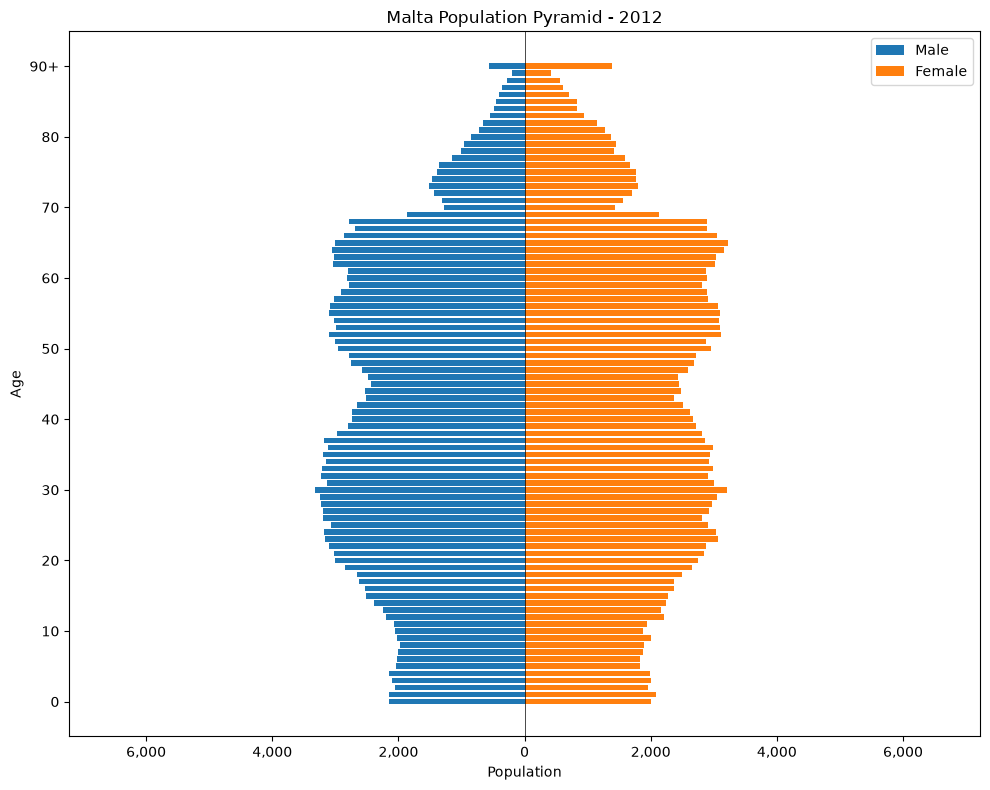

In [11]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

#Select one year's data
year = 2012
year_data = population[population["year"] == year].sort_values("age")

fig, ax = plt.subplots(figsize = (10,8))

# Negative values place male bars on the left
ax.barh(year_data["age"], -year_data["male"], label="Male")
ax.barh(year_data["age"], year_data["female"], label="Female")

# Keep the same scale for both sides and all years
limit = max(max_male, max_female) * 1.1
ax.set_xlim(-limit, limit)

# Display positive population numbers on both sides
ax.xaxis.set_major_formatter(
    FuncFormatter(lambda value, position: f"{abs(value):,.0f}")
)

ages = list(range(0, 91, 10))
ax.set_yticks(ages)
ax.set_yticklabels([str(age) if age < 90 else "90+" for age in ages])

ax.set_title(f"Malta Population Pyramid - {year}")
ax.set_xlabel("Population")
ax.set_ylabel("Age")
ax.axvline(0, color="black", linewidth=0.5)
ax.legend()

plt.tight_layout()
plt.show()

In [14]:
import os

# Use a separate folder for your generated charts
image_folder = osp.join("img", "generated")
os.makedirs(image_folder, exist_ok=True)

image_paths = []

for year in sorted(population["year"].unique()):
    year_data = population[
        population["year"] == year
    ].sort_values("age")

    fig, ax = plt.subplots(figsize=(10, 8))

    ax.barh(year_data["age"], -year_data["male"], label="Male")
    ax.barh(year_data["age"], year_data["female"], label="Female")

    ax.set_xlim(-limit, limit)
    ax.xaxis.set_major_formatter(
        FuncFormatter(lambda value, position: f"{abs(value):,.0f}")
    )

    ax.set_yticks(ages)
    ax.set_yticklabels([
        str(age) if age < 90 else "90+" for age in ages
    ])

    ax.set_title(f"Malta Population Pyramid - {year}")
    ax.set_xlabel("Population")
    ax.set_ylabel("Age")
    ax.axvline(0, color="black", linewidth=0.5)
    ax.legend()

    fig.tight_layout()

    image_path = osp.join(
        image_folder, f"malta_population_{year}.png"
    )
    fig.savefig(image_path)
    image_paths.append(image_path)

    plt.close(fig)

print(f"Saved {len(image_paths)} charts to {image_folder}")

Saved 12 charts to img\generated


Saved GIF to: img\generated\malta_population_2012_2023.gif


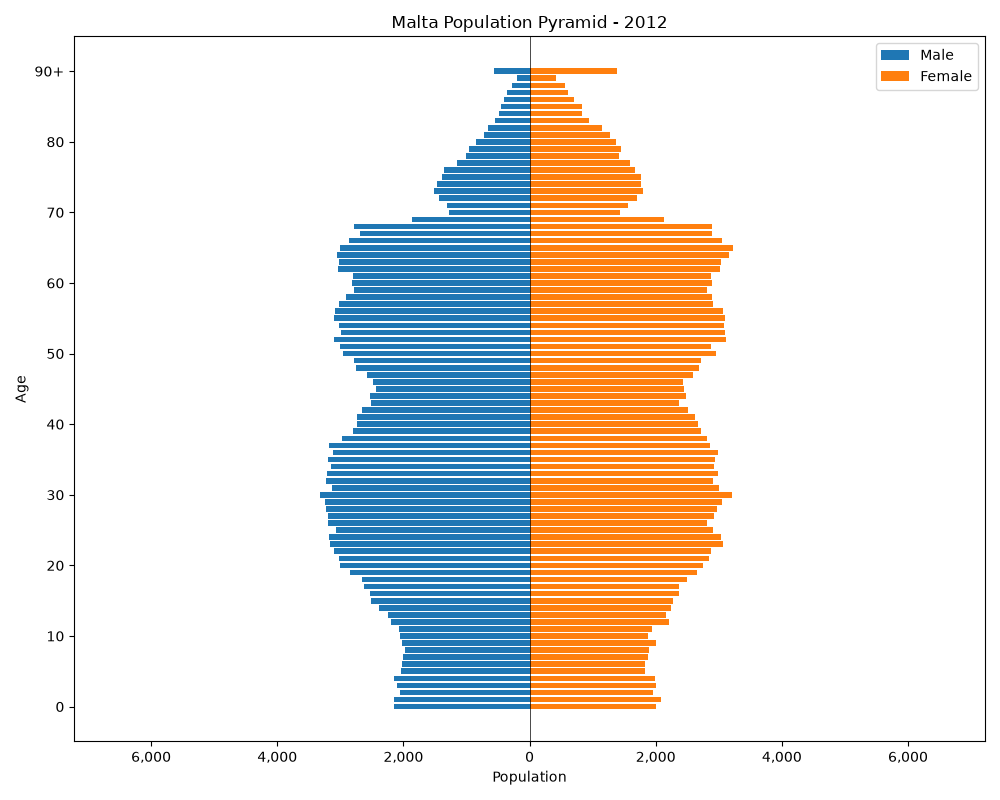

In [15]:
from PIL import Image
from IPython.display import Image as DisplayImage, display

frames = []

for image_path in image_paths:
    with Image.open(image_path) as image:   
        frames.append(image.convert("RGB"))

gif_path = osp.join(
    image_folder, "malta_population_2012_2023.gif"
)

frames[0].save(
    gif_path,
    save_all=True,
    append_images=frames[1:],
    duration=800,
    loop=0  
)

print("Saved GIF to:", gif_path)
display(DisplayImage(filename=gif_path))

## Observations and research questions

Between 2012 and 2023, Malta’s population increased across the main age groups. The population aged 15–64 grew from 287,922 to 390,555. Within this group, the difference between male and female populations also increased, with more males than females.

The population aged 65 and over increased from 72,025 to 103,406. Females outnumbered males in this group in both years. This increase in older residents raises questions about future demand for healthcare and care services.

The population aged under 15 also increased, from 61,517 to 69,482, although its growth was smaller than that of the other two groups.

The animation makes changes across years easier to see. Using the same axis scale throughout allows fair comparisons. However, the 90+ bar combines everyone aged 90 and over, so it is not directly comparable with a single-year age bar.

### Potential research questions

- How much of the growth in the working-age population is associated with migration?
- What explains the increasing difference between male and female working-age populations?
- How might the growth in residents aged 65 and over affect demand for healthcare and care services?

The charts describe changes in population structure, but additional data would be needed to explain their causes.